(lq_mean_field_games)=
```{raw} jupyter
<div id="qe-notebook-header" align="right" style="text-align:right;">
        <a href="https://quantecon.org/" title="quantecon.org">
                <img style="width:250px;display:inline;" width="250px" src="https://assets.quantecon.org/img/qe-menubar-logo.svg" alt="QuantEcon">
        </a>
</div>
```

# 线性二次平均场博弈

```{contents} Contents
:depth: 2
```

## 概览

**平均场博弈**描述了连续统的小型代理人，每个代理人求解一个动态优化问题，其收益取决于所有其他人在做什么，这由状态的横截面分布来概括。

该框架由 {cite:t}`LasryLions2007` 提出，并由 {cite:t}`HuangMalhameCaines2006` 独立提出。

它将两个偏微分方程配对：

* **哈密顿-雅可比-贝尔曼**方程，随时间反向运行，描述给定总量路径下个体的最优选择
* **柯尔莫戈罗夫前向**方程，随时间正向运行，描述给定这些选择时个体状态分布如何演化

均衡要求代理人视为给定的总量恰好是他们自己决策所产生的总量。

同一对方程也是连续时间异质代理人宏观经济学的主力工具；参见 {cite:t}`AchdouEtAl2022`。

{doc}`rational_expectations` 的读者会认出这个要求。

这就是"大 $Y$、小 $y$"的思想，现在应用于整个分布，而不是单个数字。

本讲座研究一个可处理的特殊情形，其中收益是二次的，状态呈线性演化，遵循 {cite:t}`AlvarezArgente2026`。

出现两种相互作用：

* 代理人通过矩阵 $\Theta_X$ 关心横截面平均*状态* $X$
* 代理人通过矩阵 $\Theta_{\mathcal A}$ 关心横截面平均*行动* $\mathcal A$

主要结果是一个惊人的简化：

```{note}
平均场博弈的均衡满足*单个代理人*线性二次调节器问题的代数里卡蒂方程，其中曲率矩阵 $Q$ 和 $\Gamma$ 被替换为

$$
Q + \Theta_X \qquad\text{和}\qquad \Gamma + \Theta_{\mathcal A} 。
$$
```

因此，我们对线性调节器所了解的一切都可以用于均衡分析：存在性条件、唯一性、比较静态和数值方法。

然后，我们将该框架应用于 {cite:t}`AlvarezArgente2026` 中的两个经济学例子：一个具有资本积累的行业均衡，以及一个具有金博尔需求的多产品定价问题。

里卡蒂方程也出现在其他几篇 QuantEcon 讲座中：

* {doc}`lqcontrol` 介绍了线性调节器及其里卡蒂方程
* {doc}`lagrangian_lqdp` 研究状态-协态系统及其稳定不变子空间，这正是我们下面遇到的结构
* {doc}`markov_perf` 研究*有限多个*参与者的动态博弈，其中每个参与者都有一个里卡蒂方程，且这些方程是耦合的
* {doc}`kalman` 给出了与控制问题对偶的里卡蒂方程

让我们从一些导入开始：

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import solve_continuous_are, expm

## 环境

存在连续统的代理人。

个体具有状态 $x \in \mathbb R^n$ 并采取行动 $\alpha \in \mathbb R^k$。

横截面平均状态和行动为

$$
X = \int x \, m(x) dx , \qquad
\mathcal A = \int \alpha_*(x) \, m(x) dx ,
$$

其中 $m$ 是代理人状态的密度。

期间收益对所有四个对象都是二次的：

```{math}
:label: mfg_return
F(x,X) + R(\alpha, \mathcal A)
= -\tfrac12 x^\top Q x - X^\top\Theta_X x
  -\tfrac12 \alpha^\top \Gamma \alpha - \mathcal A^\top \Theta_{\mathcal A}\alpha 。
```

个体状态遵循

```{math}
:label: mfg_state
dx = (B\alpha - Ax) dt + \Sigma^{1/2} dW ,
```

其中 $W$ 是 $n$ 维布朗运动，目前冲击纯粹是特异性的。

代理人以贴现率 $\rho > 0$ 进行贴现。

我们假设 $Q$ 和 $\Gamma$ 是正定的，$\Sigma$ 是半正定的，$B$ 具有满行秩，且 $\Theta_X$ 和 $\Theta_{\mathcal A}$ 是对称的。

### 互补品和替代品

从 {eq}`mfg_return` 可知，个体自身状态与平均状态之间的交叉导数是 $-\Theta_X$，个体自身行动与平均行动之间的交叉导数是 $-\Theta_{\mathcal A}$。

因此

* 当 $-\Theta_X$ 是正定时，状态是**战略互补品**，即当 $\Theta_X$ 是负定时
* 当 $\Theta_X$ 是正定时，状态是**战略替代品**

对于行动也是类似的。

在洛纳序中，*更小*的 $\Theta$ 意味着*更强*的互补性。

```{note}
{cite:t}`LasryLions2007` 为获得唯一性而施加的单调性条件，在此对应于 $-\Theta_X$ 是半负定的，即状态中的战略*替代性*。

我们不需要这个条件：在这个线性二次设置中，无论相互作用是互补还是替代，至多存在一个均衡。
```

### 均衡

给定路径 $\{X(t), \mathcal A(t)\}$，代理人的价值函数满足 HJB 方程

```{math}
:label: mfg_hjb
\rho u(x,t) = -\tfrac12 x^\top Qx - X(t)^\top\Theta_X x
 + H(u_x(x,t), x, \mathcal A(t))
 + \tfrac12 \operatorname{tr}(\Sigma u_{xx}(x,t)) + u_t(x,t) ,
```

其中哈密顿量为

$$
H(p, x, \mathcal A) = \max_{\alpha}
\left\{ -\tfrac12\alpha^\top\Gamma\alpha - \mathcal A^\top\Theta_{\mathcal A}\alpha
+ p^\top(B\alpha - Ax) \right\} ,
$$

最大化器为 $\alpha_*(p,\mathcal A) = \Gamma^{-1}(B^\top p - \Theta_{\mathcal A}\mathcal A)$。

密度根据柯尔莫戈罗夫前向方程演化

```{math}
:label: mfg_kfe
m_t(x,t) = -\operatorname{div}\left( H_p(u_x(x,t),x,\mathcal A(t)) m(x,t)\right)
+ \tfrac12 \operatorname{tr}(\Sigma m_{xx}(x,t)) ,
```

**均衡**是一个价值函数、一个密度以及 $X$ 和 $\mathcal A$ 的路径，满足 {eq}`mfg_hjb`、{eq}`mfg_kfe`，以及 $X$ 和 $\mathcal A$ 确实是 $m$ 和最优策略所暗示的横截面平均值这一一致性要求。

## 求解个体问题

给定总量路径，个体面临一个时变线性二次调节器问题，因此她的价值函数是二次的：

$$
u(x,t) = \beta_0(t) + \beta_1(t)^\top x + \tfrac12 x^\top\beta_2(t)x 。
$$

代入 {eq}`mfg_hjb` 并匹配各阶项给出三个微分方程。

$\beta_2$ 的方程为

```{math}
:label: mfg_beta2_ode
\dot\beta_2 = Q - \beta_2 B\Gamma^{-1}B^\top\beta_2 + \beta_2 A + A^\top\beta_2 + \rho\beta_2 。
```

注意 {eq}`mfg_beta2_ode` 中*缺失*了什么：两个相互作用矩阵都没有出现。

因此，个体价值函数的曲率与她独自一人生活在世界上时相同。

由于个体问题是凹的和平稳的，$\beta_2(t)$ 等于常数 $\bar\beta_2$，即以下方程的负定解

```{math}
:label: mfg_beta2
\bar\beta_2 B\Gamma^{-1}B^\top\bar\beta_2 = Q + \rho\bar\beta_2 + \bar\beta_2 A + A^\top\bar\beta_2 。
```

这是 {doc}`lqcontrol` 中熟悉的代数里卡蒂方程，以连续时间形式写出。

最优行动为

$$
\alpha_*(x,t) = \Gamma^{-1}\left[B^\top(\beta_1(t) + \bar\beta_2 x) - \Theta_{\mathcal A}\mathcal A(t)\right] 。
$$

对代理人求平均，并求解 $\mathcal A$ 中的不动点，得到

```{math}
:label: mfg_aggregate_action
\mathcal A(t) = (\Gamma + \Theta_{\mathcal A})^{-1} B^\top \left(\beta_1(t) + \bar\beta_2 X(t)\right) 。
```

方程 {eq}`mfg_aggregate_action` 正是行动相互作用首次发挥作用的地方：每个代理人都对平均行动做出反应，求解与人人如此一致的平均值，将 $\Gamma$ 替换为 $\Gamma + \Theta_{\mathcal A}$。

## 状态-协态系统

现在还剩下两个对象：价值函数的线性系数 $\beta_1(t)$ 和总量状态 $X(t)$。

求导并加总得到一对线性微分方程，

```{math}
:label: mfg_hamiltonian_system
\begin{bmatrix} \dot\beta_1 \\ \dot X \end{bmatrix}
= \mathcal H \begin{bmatrix} \beta_1 \\ X\end{bmatrix},
\qquad
\mathcal H =
\begin{bmatrix}
\rho I + A^\top - \bar\beta_2 \Lambda & \Theta_X + \bar\beta_2(B\Gamma^{-1}B^\top - \Lambda)\bar\beta_2 \\
\Lambda & -A + \Lambda\bar\beta_2
\end{bmatrix},
```

其中我们简写为

$$
\Lambda \equiv B(\Gamma + \Theta_{\mathcal A})^{-1}B^\top 。
$$

这正是 {doc}`lagrangian_lqdp` 中研究的那种**状态-协态**系统。

总量状态 $X$ 有一个初始条件，即初始分布的均值。

协态 $\beta_1$ 没有初始条件：它必须被选择，使得解不违反代理人的横截性条件，这里要求支配路径的特征值实部低于 $\rho/2$。

由于 $\Theta_X$、$B\Gamma^{-1}B^\top$ 和 $\Lambda$ 是对称的，$\mathcal H - \tfrac\rho2 I$ 是一个哈密顿矩阵，因此其特征值关于原点对称。

等价地：

```{prf:proposition}
:label: mfg_prop_roots

如果 $\lambda$ 是 $\mathcal H$ 的特征值，那么 $\rho - \lambda$、$\bar\lambda$ 和 $\rho - \bar\lambda$ 也是。
```

因此恰好有 $n$ 个特征值的实部可以低于 $\rho/2$，这确定了唯一的稳定不变子空间，因而至多存在一个均衡。

这是代数里卡蒂方程与哈密顿矩阵不变子空间之间的标准联系，{cite:t}`LancasterRodman1995` 对此有详尽论述。

## 均衡里卡蒂方程

我们寻找一条鞍路径，沿着这条路径协态是状态的线性函数，$\beta_1(t) = S X(t)$。

代入 {eq}`mfg_hamiltonian_system` 得到 $S$ 的一个二次矩阵方程，其系数涉及 $\bar\beta_2$。

那个方程看起来令人望而生畏，但一个变量替换可以转化它。

定义

$$
P \equiv S + \bar\beta_2 。
$$

```{prf:proposition}
:label: mfg_prop_riccati

均衡的特征是一个矩阵 $P$ 满足

$$
P \, B(\Gamma+\Theta_{\mathcal A})^{-1}B^\top \, P
= Q + \Theta_X + \rho P + PA + A^\top P ,
$$

总量动态为

$$
\dot X = \left(B(\Gamma+\Theta_{\mathcal A})^{-1}B^\top P - A\right) X 。
$$

均衡要求闭环矩阵的所有特征值实部低于 $\rho/2$。
```

将此与单个代理人的方程 {eq}`mfg_beta2` 比较。

它们具有*相同的形式*。

唯一的区别是 $Q$ 变成了 $Q + \Theta_X$，$\Gamma$ 变成了 $\Gamma + \Theta_{\mathcal A}$。

```{prf:proposition}
:label: mfg_prop_equivalence

具有相互作用矩阵 $\Theta_X$ 和 $\Theta_{\mathcal A}$ 的线性二次平均场博弈的均衡及其总量运动定律，与状态曲率为 $Q+\Theta_X$、行动曲率为 $\Gamma+\Theta_{\mathcal A}$ 的单代理人线性二次控制问题的解相一致。
```

这是本讲座的核心组织性结果。

它说明战略相互作用并不改变决定总量动态的问题的*形式*；它改变的是进入该问题的*曲率*。

一个直接的经济学含义是：两个战略相互作用非常不同的模型，只要有效曲率一致，就可以产生完全相同的总量动态。

### 存在性和唯一性

由于 $P$ 满足一个标准的里卡蒂方程，标准条件适用。

定义

```{math}
:label: mfg_E
E \equiv Q + \Theta_X + \left(A^\top + \tfrac\rho2 I\right)
\left[B(\Gamma+\Theta_{\mathcal A})^{-1}B^\top\right]^{-1}
\left(A + \tfrac\rho2 I\right) 。
```

```{prf:proposition}
:label: mfg_prop_existence

假设 $B(\Gamma+\Theta_{\mathcal A})^{-1}B^\top$ 可逆。

1. 均衡存在的必要条件是 $E$ 半正定。
1. 如果 $Q + \Theta_X$ 和 $\Gamma + \Theta_{\mathcal A}$ 是正定的，则均衡存在且唯一。
1. 至多存在一个均衡。
```

充分条件有一个清晰的解读：*有效*曲率在状态和行动上都必须保持为正。

因此互补性是被允许的，但只能到一定程度。

还要注意，两种相互作用以加法方式进入 $E$，因此行动中的替代性可以抵消状态中的互补性。

## 计算均衡

`scipy.linalg.solve_continuous_are(A, B, Q, R)` 返回以下方程的稳定解 $\tilde P$：

$$
A^\top \tilde P + \tilde P A - \tilde P B R^{-1} B^\top \tilde P + Q = 0 。
$$

我们的方程在两个方面有所不同：我们的 $P$ 是负定的，并且我们进行贴现。

写作 $P = -\tilde P$ 并整理各项表明，我们的方程是标准方程，其中 $A$ 被替换为 $-(A + \tfrac\rho2 I)$。

贴现率的进入方式恰好与连续时间控制中熟悉的"$\rho/2$ 移位"相同。

In [2]:
def mfg_riccati(A, B, Q, Γ, ρ):
    """
    Solve  P B Γ^{-1} B' P = Q + ρ P + P A + A' P  for the negative
    definite stabilizing solution P.

    Passing Q + Θ_X and Γ + Θ_A gives the equilibrium of the mean field game;
    passing Q and Γ gives the single agent's value function curvature.
    """
    n = A.shape[0]
    return -solve_continuous_are(-(A + ρ/2 * np.eye(n)), B, Q, Γ)

def closed_loop(A, B, Γ_eff, P):
    "The matrix governing aggregate dynamics, Ẋ = (B Γ_eff^{-1} B' P - A) X."
    return B @ np.linalg.solve(Γ_eff, B.T) @ P - A

让我们建立一个二维例子，其中状态存在互补性，行动存在替代性，这是 {cite:t}`AlvarezArgente2026` 从具有资本积累的行业均衡中获得的配置。

In [3]:
ρ = 0.05
A = np.array([[0.4, 0.1],
              [0.0, 0.3]])
B = np.eye(2)
Q = np.array([[1.0, 0.2],
              [0.2, 0.8]])
Γ = np.array([[1.0, 0.1],
              [0.1, 1.2]])
Θ_X = np.array([[-0.3, 0.05],     # negative definite: complements in states
                [0.05, -0.2]])
Θ_A = np.array([[0.2, 0.0],       # positive definite: substitutes in actions
                [0.0, 0.1]])

β2 = mfg_riccati(A, B, Q, Γ, ρ)                 # single agent
P = mfg_riccati(A, B, Q + Θ_X, Γ + Θ_A, ρ)      # equilibrium

print("individual curvature β̄₂ =\n", β2.round(4))
print("\nequilibrium matrix P =\n", P.round(4))

individual curvature β̄₂ =
 [[-0.6614 -0.0869]
 [-0.0869 -0.654 ]]

equilibrium matrix P =
 [[-0.5353 -0.134 ]
 [-0.134  -0.5337]]


让我们验证 $P$ 确实满足均衡里卡蒂方程，并将总量动态与单个代理人独自会选择的动态进行比较。

In [4]:
Λ = B @ np.linalg.solve(Γ + Θ_A, B.T)
residual = P @ Λ @ P - (Q + Θ_X + ρ*P + P @ A + A.T @ P)
print(f"Riccati residual: {np.abs(residual).max():.2e}")

G = closed_loop(A, B, Γ, β2)          # dynamics without any interaction
JG = closed_loop(A, B, Γ + Θ_A, P)    # equilibrium dynamics

print("\neigenvalues without interactions:", np.linalg.eigvals(G).round(4))
print("eigenvalues in equilibrium:       ", np.linalg.eigvals(JG).round(4))

Riccati residual: 2.50e-16

eigenvalues without interactions: [-1.0698 -0.8321]
eigenvalues in equilibrium:        [-0.9025 -0.6423]


均衡特征值更接近于零，因此总量调整比每个代理人忽略其他人时更慢。

### 检验哈密顿结构

{prf:ref}`mfg_prop_roots` 表明 $\mathcal H$ 的特征值成对出现 $\{\lambda, \rho - \lambda\}$，且实部低于 $\rho/2$ 的 $n$ 个特征值是支配均衡动态的那些。

让我们检验这两个论断。

In [5]:
BΓB = B @ np.linalg.solve(Γ, B.T)
n = A.shape[0]

H = np.block([[ρ*np.eye(n) + A.T - β2 @ Λ, Θ_X + β2 @ (BΓB - Λ) @ β2],
              [Λ,                          -A + Λ @ β2]])

ev = np.linalg.eigvals(H)
print("eigenvalues of ℋ:", np.sort(ev.real).round(4))
print("paired as λ and ρ - λ:",
      np.allclose(np.sort(ev.real), np.sort(ρ - ev.real)))

stable = np.sort(ev.real[ev.real < ρ/2])
print("\nstable half of ℋ:      ", stable.round(4))
print("closed-loop eigenvalues:", np.sort(np.linalg.eigvals(JG).real).round(4))

eigenvalues of ℋ: [-0.9025 -0.6423  0.6923  0.9525]
paired as λ and ρ - λ: True

stable half of ℋ:       [-0.9025 -0.6423]
closed-loop eigenvalues: [-0.9025 -0.6423]


鞍路径恰好是 $\mathcal H$ 的稳定不变子空间，与 {doc}`lagrangian_lqdp` 中完全一致。

## 标量情形

当 $n = k = 1$ 时，一切都是显式的。

用 $q, a, b, \gamma, \theta_X, \theta_{\mathcal A}$ 表示标量。

里卡蒂方程变成一个二次方程，可容许的根给出总量特征值

```{math}
:label: mfg_scalar_lambda
\lambda = \frac\rho2 - \sqrt{\left(\frac\rho2 + a\right)^2
+ \frac{b^2(q + \theta_X)}{\gamma + \theta_{\mathcal A}}} 。
```

当且仅当根号下的项为正时均衡存在，

```{math}
:label: mfg_scalar_existence
q + \theta_X + \left(\frac\rho2+a\right)^2\frac{\gamma+\theta_{\mathcal A}}{b^2} > 0 ,
```

均衡是稳定的（即 $\lambda<0$）当且仅当

```{math}
:label: mfg_scalar_stability
q + \theta_X + a(a+\rho)\frac{\gamma+\theta_{\mathcal A}}{b^2} > 0 。
```

公式 {eq}`mfg_scalar_lambda` 一目了然地展示了两种比较静态。

*状态*中更强的互补性（更小的 $\theta_X$）提高了 $\lambda$，使总量动态*更加*持久：当其他人远离稳态时，每个代理人也就没有那么强的动机回归稳态。

*行动*中更强的互补性（更小的 $\theta_{\mathcal A}$）降低了 $\lambda$，使动态*更不*持久：当其他人调整时，每个代理人也想调整。

让我们确认我们的求解器能再现 {eq}`mfg_scalar_lambda`。

In [6]:
def scalar_lambda(ρ, a, b, q, γ, θ_X, θ_A):
    "Closed-form aggregate eigenvalue in the scalar case."
    return ρ/2 - np.sqrt((ρ/2 + a)**2 + b**2*(q + θ_X)/(γ + θ_A))

ρ_s, a, b, q, γ = 0.05, 0.3, 1.0, 1.0, 1.0

print(f"{'θ_X':>6}{'θ_A':>6}{'solver':>12}{'closed form':>14}")
for θ_X, θ_A in ((0.0, 0.0), (-0.5, 0.0), (0.0, 0.5), (-0.5, 0.5)):
    P_s = mfg_riccati(np.array([[a]]), np.array([[b]]),
                      np.array([[q + θ_X]]), np.array([[γ + θ_A]]), ρ_s)
    λ_num = closed_loop(np.array([[a]]), np.array([[b]]),
                        np.array([[γ + θ_A]]), P_s)[0, 0]
    print(f"{θ_X:>6}{θ_A:>6}{λ_num:>12.6f}{scalar_lambda(ρ_s,a,b,q,γ,θ_X,θ_A):>14.6f}")

   θ_X   θ_A      solver   closed form
   0.0   0.0   -1.026487     -1.026487
  -0.5   0.0   -0.753219     -0.753219
   0.0   0.5   -0.853801     -0.853801
  -0.5   0.5   -0.637539     -0.637539


## 具有资本积累的行业均衡

标量模型并非玩具。

{cite:t}`AlvarezArgente2026` 表明，它描述了一个既存在两种相互作用、且符号相反的具有资本积累的行业均衡。

存在连续统的垄断竞争企业。

一个拥有资本 $k$ 的企业生产 $y = k^\nu$，其中 $0 < \nu < 1$，一个规模报酬不变的部门以替代弹性 $\eta > 1$ 加总这些差异化商品。

以最终商品作为计价商品，当行业产出为 $Y$ 时生产 $y$ 的企业获得的收入与 $y^{1-1/\eta}Y^{1/\eta}$ 成正比。

因此，如果其他所有企业都持有资本 $K$，经营利润与以下成正比

```{math}
:label: mfg_capital_profit
\Pi(k,K) = k^{\nu(1 - 1/\eta)} K^{\nu/\eta} 。
```

资本演化遵循

$$
dk = (i - \delta k)dt + k \sigma dW ,
$$

企业以价格 $\mathcal P(I)$ 购买投资品，其中 $I$ 是总投资，它还支付一个凸调整成本 $\psi(i)$。

设 $\bar i = \delta \bar k$ 为稳态投资，将 $\mathcal P(\bar i) = 1$ 和 $\psi'(\bar i) = 0$ 归一化，并将偏离确定性稳态的百分比偏差写为

$$
x = \frac{k - \bar k}{\bar k}, \qquad
X = \frac{K - \bar k}{\bar k}, \qquad
\alpha = \frac{i - \bar i}{\bar i}, \qquad
\mathcal A = \frac{I - \bar i}{\bar i} 。
$$

围绕稳态对收益进行二阶展开，将目标函数用 $\bar\Pi \equiv \Pi(\bar k, \bar k)$ 归一化，恰好得到 {eq}`mfg_return` 的形式，其中

$$
q = -\frac{\bar k^2 \Pi_{kk}}{\bar\Pi}, \qquad
\theta_X = -\frac{\bar k^2 \Pi_{kK}}{\bar\Pi}, \qquad
\gamma = \frac{\delta^2\bar k^2 \psi''(\bar i)}{\bar\Pi}, \qquad
\theta_{\mathcal A} = \frac{\delta^2\bar k^2 \mathcal P'(\bar i)}{\bar\Pi} ,
$$

而状态方程一阶近似变为 $dx = \delta(\alpha - x)dt + \sigma dW$，因此

$$
a = b = \delta 。
$$

对 {eq}`mfg_capital_profit` 求导给出闭式表达式：

```{math}
:label: mfg_capital_coeffs
\begin{aligned}
q &= \nu\frac{\eta-1}{\eta^2}\left[\eta(1-\nu) + \nu\right] > 0 , \\
\theta_X &= -\frac{\eta-1}{\eta}\frac{\nu^2}{\eta} < 0 , \\
q + \theta_X &= \frac{\eta-1}{\eta}\nu(1-\nu) > 0 。
\end{aligned}
```

{eq}`mfg_capital_coeffs` 有三个特征值得强调。

第一，$\theta_X < 0$：资本存量是战略*互补品*，因为更大的行业资本存量提高了需求转移变量 $Y^{1/\eta}$，从而提高了企业自身资本的边际盈利能力。

第二，如果投资品的供给曲线向上倾斜，那么 $\mathcal P'(\bar i) > 0$，因而 $\theta_{\mathcal A} > 0$：投资率是战略*替代品*，因为所有人同时投资会抬高资本品的价格。

第三，对于每一个 $\eta > 1$ 和每一个 $\nu \in (0,1)$，都有 $q + \theta_X > 0$，因此根据 {prf:ref}`mfg_prop_existence`，无论市场势力多强、规模报酬多接近不变，均衡都存在且唯一。

让我们把这些公式写成代码，并与利润函数本身的数值导数进行比较。

In [7]:
def cap_q(η, ν):
    "Own-state curvature in the capital accumulation example."
    return ν*(η - 1)/η**2*(η*(1 - ν) + ν)

def cap_θ_X(η, ν):
    "State interaction in the capital accumulation example."
    return -(η - 1)/η*ν**2/η

η_c, ν_c = 4.0, 0.7

Π = lambda k, K: k**(ν_c*(1 - 1/η_c))*K**(ν_c/η_c)

h = 1e-5
Π_kk = (Π(1+h, 1) - 2*Π(1, 1) + Π(1-h, 1))/h**2
Π_kK = (Π(1+h, 1+h) - Π(1+h, 1-h) - Π(1-h, 1+h) + Π(1-h, 1-h))/(4*h**2)

print(f"{'':>10}{'finite difference':>20}{'closed form':>15}")
print(f"{'q':>10}{-Π_kk/Π(1, 1):>20.6f}{cap_q(η_c, ν_c):>15.6f}")
print(f"{'θ_X':>10}{-Π_kK/Π(1, 1):>20.6f}{cap_θ_X(η_c, ν_c):>15.6f}")
print(f"{'q + θ_X':>10}{-(Π_kk + Π_kK)/Π(1, 1):>20.6f}"
      f"{(η_c - 1)/η_c*ν_c*(1 - ν_c):>15.6f}")

             finite difference    closed form
         q            0.249374       0.249375
       θ_X           -0.091875      -0.091875
   q + θ_X            0.157499       0.157500


### 校准

采用年度单位，$\delta = 0.10$，$\rho = 0.05$，替代弹性 $\eta = 4$，规模报酬 $\nu = 0.7$。

对于技术无法确定的两个曲率，我们设置 $\gamma = 0.05$，这使得忽略行业的企业在三年内弥合一半的资本缺口，同时设置 $\theta_{\mathcal A} = 0.09$。

{ref}`mfg_ex5` 从调整成本函数和投资供给曲线推导了这两个数字。

In [8]:
ρ_c, δ_c = 0.05, 0.10
γ_c, θ_A_c = 0.05, 0.09

q_c, θ_X_c = cap_q(η_c, ν_c), cap_θ_X(η_c, ν_c)

def half_life(λ):
    "Time for the aggregate state to close half of a gap."
    return np.log(2)/(-λ)

λ_c = scalar_lambda(ρ_c, δ_c, δ_c, q_c, γ_c, θ_X_c, θ_A_c)

P_c = mfg_riccati(np.array([[δ_c]]), np.array([[δ_c]]),
                  np.array([[q_c + θ_X_c]]), np.array([[γ_c + θ_A_c]]), ρ_c)
λ_c_solver = closed_loop(np.array([[δ_c]]), np.array([[δ_c]]),
                         np.array([[γ_c + θ_A_c]]), P_c)[0, 0]

print(f"q = {q_c:.4f},  θ_X = {θ_X_c:.4f},  q + θ_X = {q_c + θ_X_c:.4f}")
print(f"λ from the solver      = {λ_c_solver:.6f}")
print(f"λ from the closed form = {λ_c:.6f}")
print(f"half-life of aggregate capital = {half_life(λ_c):.2f} years")

q = 0.2494,  θ_X = -0.0919,  q + θ_X = 0.1575
λ from the solver      = -0.138936
λ from the closed form = -0.138936
half-life of aggregate capital = 4.99 years


### 这些相互作用有多重要？

由于 {eq}`mfg_scalar_lambda` 分别依赖于 $\theta_X$ 和 $\theta_{\mathcal A}$，我们可以关闭每种相互作用来读出答案。

In [9]:
cases = {'no interactions':            (0.0,     0.0),
         'state complementarity only': (θ_X_c,   0.0),
         'action substitutability only': (0.0,   θ_A_c),
         'equilibrium':                (θ_X_c,   θ_A_c),
         'planner (both doubled)':     (2*θ_X_c, 2*θ_A_c)}

print(f"{'':>30}{'λ':>10}{'half-life':>12}")
for label, (tx, ta) in cases.items():
    λ_case = scalar_lambda(ρ_c, δ_c, δ_c, q_c, γ_c, tx, ta)
    print(f"{label:>30}{λ_case:>10.4f}{half_life(λ_case):>12.2f}")

                                       λ   half-life
               no interactions   -0.2309        3.00
    state complementarity only   -0.1921        3.61
  action substitutability only   -0.1579        4.39
                   equilibrium   -0.1389        4.99
        planner (both doubled)   -0.1109        6.25


两种相互作用都会减缓总量资本的调整速度，但原因不同。

状态中的互补性意味着，当行业其余部分仍低于其稳态时，企业重建资本的理由较少。

行动中的替代性意味着行业投资的一次性激增代价高昂，因此企业会将投资分散到不同时期。

两者共同将行业资本存量的半衰期从三年拉长到五年。

将这两种外部性都内化的计划者则更慢。

### 微观和宏观调整速度

该模型的一个显著预测是，个体资本回归均值的速度比总量资本更快，因为 {eq}`mfg_beta2` 中没有相互作用矩阵。

In [10]:
β2_c = mfg_riccati(np.array([[δ_c]]), np.array([[δ_c]]),
                   np.array([[q_c]]), np.array([[γ_c]]), ρ_c)
λ_micro = closed_loop(np.array([[δ_c]]), np.array([[δ_c]]),
                      np.array([[γ_c]]), β2_c)[0, 0]

print(f"individual half-life = {half_life(λ_micro):.2f} years")
print(f"aggregate  half-life = {half_life(λ_c):.2f} years")
print(f"ratio                = {half_life(λ_c)/half_life(λ_micro):.2f}")

individual half-life = 3.00 years
aggregate  half-life = 4.99 years
ratio                = 1.66


若研究人员从企业层面的数据估计资本调整速度，然后用它来预测行业对全行业冲击的反应速度有多快，那么其预测速度将比实际快三分之二。

这个差距是一个纯粹的相互作用效应：相同的技术和相同的调整成本产生了这两个数字。

### 市场势力和规模报酬

行业的调整速度如何取决于这两个技术参数？

两者都只通过 $q + \theta_X = \frac{\eta-1}{\eta}\nu(1-\nu)$ 起作用，该值随 $\eta$ 上升，并在 $\nu = 1/2$ 处取得最大值。

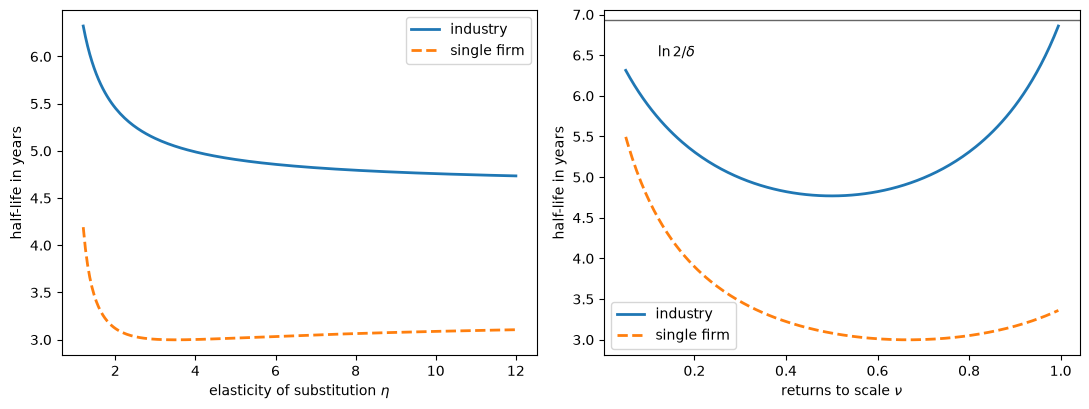

In [11]:
η_grid = np.linspace(1.2, 12, 200)
ν_grid = np.linspace(0.05, 0.995, 200)

def macro_micro(η, ν):
    "Aggregate and individual half-lives as functions of (η, ν)."
    q, θ_X = cap_q(η, ν), cap_θ_X(η, ν)
    λ_agg = scalar_lambda(ρ_c, δ_c, δ_c, q, γ_c, θ_X, θ_A_c)
    λ_ind = scalar_lambda(ρ_c, δ_c, δ_c, q, γ_c, 0.0, 0.0)
    return half_life(λ_agg), half_life(λ_ind)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))

hl_agg, hl_ind = np.array([macro_micro(η, ν_c) for η in η_grid]).T
axes[0].plot(η_grid, hl_agg, lw=2, label='industry')
axes[0].plot(η_grid, hl_ind, lw=2, ls='--', label='single firm')
axes[0].set_xlabel('elasticity of substitution $\\eta$')

hl_agg, hl_ind = np.array([macro_micro(η_c, ν) for ν in ν_grid]).T
axes[1].plot(ν_grid, hl_agg, lw=2, label='industry')
axes[1].plot(ν_grid, hl_ind, lw=2, ls='--', label='single firm')
axes[1].axhline(np.log(2)/δ_c, color='k', lw=1, alpha=0.6)
axes[1].set_xlabel('returns to scale $\\nu$')
axes[1].annotate('$\\ln 2/\\delta$', (0.12, np.log(2)/δ_c - 0.45))

for ax in axes:
    ax.set_ylabel('half-life in years')
    ax.legend()
plt.tight_layout()
plt.show()

更强的市场势力，即更小的 $\eta$，使行业变得更慢：它削弱了自身资本曲率相对于相互作用的强度，左侧面板显示行业半衰期随 $\eta$ 下降而上升。

右侧面板包含一个更为尖锐的结果。

随着 $\nu \to 1$，有效曲率 $q + \theta_X$ 趋于消失，{eq}`mfg_scalar_lambda` 收缩为 $\lambda \to -\delta$：此时行业的资本存量只能通过折旧回归其稳态，总量投资根本不做反应。

{ref}`mfg_ex6` 要求你验证这一极限并解释它。

### 我们处在四个区域中的哪一个？

{ref}`mfg_ex1` 使用阈值 $-\theta^{*}$ 和 $-\theta^{**}$ 将标量模型划分为四个区域。

由于技术给出 $q + \theta_X > 0$，而向上倾斜的投资供给给出 $\theta_{\mathcal A} > 0$，这个例子始终处于第一个区域。

阈值显示了有多大的余地。

In [12]:
mθ_star = q_c + δ_c*(δ_c + ρ_c)*(γ_c + θ_A_c)/δ_c**2
mθ_2star = q_c + (ρ_c/2 + δ_c)**2*(γ_c + θ_A_c)/δ_c**2

print(f"complementarity in the calibration, -θ_X = {-θ_X_c:.4f}")
print(f"instability threshold,          -θ*     = {mθ_star:.4f}")
print(f"nonexistence threshold,         -θ**    = {mθ_2star:.4f}")

complementarity in the calibration, -θ_X = 0.0919
instability threshold,          -θ*     = 0.4594
nonexistence threshold,         -θ**    = 0.4681


互补性需要比技术所暗示的强五倍，才会使行业资本存量停止收敛。

### 过渡路径

最后，让我们描绘出行业对起始高于稳态百分之十的资本存量的反应。

总量投资由 {eq}`mfg_aggregate_action` 推得，在标量情形下给出 $\mathcal A(t) = \frac{\lambda + \delta}{\delta}X(t)$。

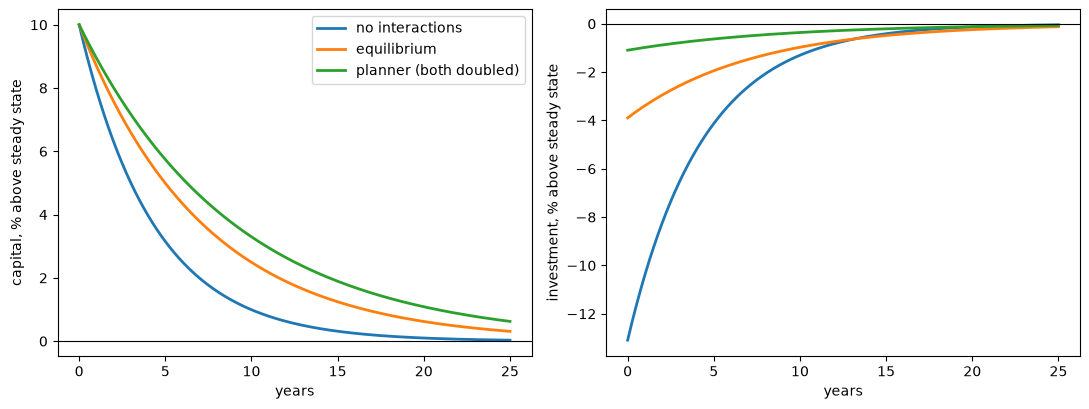

In [13]:
t_c = np.linspace(0, 25, 300)
X0_c = 0.10

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for label in ('no interactions', 'equilibrium', 'planner (both doubled)'):
    tx, ta = cases[label]
    λ_case = scalar_lambda(ρ_c, δ_c, δ_c, q_c, γ_c, tx, ta)
    path = X0_c*np.exp(λ_case*t_c)
    axes[0].plot(t_c, 100*path, lw=2, label=label)
    axes[1].plot(t_c, 100*(λ_case + δ_c)/δ_c*path, lw=2, label=label)

axes[0].set_ylabel('capital, % above steady state')
axes[1].set_ylabel('investment, % above steady state')
for ax in axes:
    ax.set_xlabel('years')
    ax.axhline(0, color='k', lw=0.8)
axes[0].legend()
plt.tight_layout()
plt.show()

右侧面板是行业的投资反应，这里最清楚地展示了两种相互作用。

一个忽略行业的企业会在冲击发生时立即将投资削减其稳态水平的百分之十三；而在均衡中，削减幅度不到百分之四，且撤销速度慢得多。

支撑这些路径的协态 $\beta_1(t) + \bar\beta_2 x$ 是已安装资本的边际价值，即托宾的 $q$。

{doc}`optimal_growth_uncertainty` 在约束 $i \geq 0$ 起作用、价值函数并非处处可微的设定下研究了这个对象，而这恰恰是此处二次近似所忽略的非线性。


## 持久性

当 $n > 1$ 时，相互作用如何改变总量调整？

无论哪种类型，更强的互补性都使稳定解 $P$ 变得不那么负定。

这种排序不足以确定闭环矩阵每个特征值变化的符号，但它确实确定了它们*总和*变化的符号。

状态中更强的互补性提高了闭环矩阵的迹，而行动中更强的互补性降低了它。

迹衡量了一组总量初始状态在遵循各自均衡路径时体积收缩的速率，因此在稳定均衡中，第一种力量减缓了向稳态的坍缩，而第二种力量加速了它。

In [14]:
print(f"{'scale on Θ_X':>14}{'trace':>10}   eigenvalues")
for scale in (0.0, 0.5, 1.0, 1.5):
    P_s = mfg_riccati(A, B, Q + scale*Θ_X, Γ + Θ_A, ρ)
    JG_s = closed_loop(A, B, Γ + Θ_A, P_s)
    print(f"{scale:>14}{np.trace(JG_s):>10.4f}   {np.linalg.eigvals(JG_s).real.round(4)}")

  scale on Θ_X     trace   eigenvalues
           0.0   -1.7933   [-0.9956 -0.7977]
           0.5   -1.6747   [-0.9485 -0.7262]
           1.0   -1.5448   [-0.9025 -0.6423]
           1.5   -1.3988   [-0.857  -0.5418]


提高比例使 $\Theta_X$ 更负，即互补性更强，正如所声称的那样，迹随之上升。

{ref}`mfg_ex2` 要求你研究*每个*特征值是否必须朝同一方向移动。

## 计划者

功利主义计划者将每个代理人的状态和行动对相应横截面平均值的影响内在化。

当 $\Theta_X$ 和 $\Theta_{\mathcal A}$ 是对称时，对计划者的目标函数求导会使每个相互作用项加倍。

```{prf:proposition}
:label: mfg_prop_planner

计划者的配置与相互作用矩阵为 $2\Theta_X$ 和 $2\Theta_{\mathcal A}$ 的经济体的分散均衡相一致，因此计划者的里卡蒂方程为

$$
P^{*} B(\Gamma + 2\Theta_{\mathcal A})^{-1}B^\top P^{*}
= Q + 2\Theta_X + \rho P^{*} + P^{*}A + A^\top P^{*} 。
$$
```

将状态互补性内在化使配置*更加*持久，而将行动互补性内在化使其*更不*持久。

当两者同时存在时，比较结果是不明确的，正如 {ref}`mfg_ex3` 所探讨的那样。

In [15]:
P_planner = mfg_riccati(A, B, Q + 2*Θ_X, Γ + 2*Θ_A, ρ)
JG_planner = closed_loop(A, B, Γ + 2*Θ_A, P_planner)

print("equilibrium eigenvalues:", np.linalg.eigvals(JG).real.round(4))
print("planner eigenvalues:    ", np.linalg.eigvals(JG_planner).real.round(4))

equilibrium eigenvalues: [-0.9025 -0.6423]
planner eigenvalues:     [-0.7786 -0.4039]


让我们看看这对总量状态的路径意味着什么。

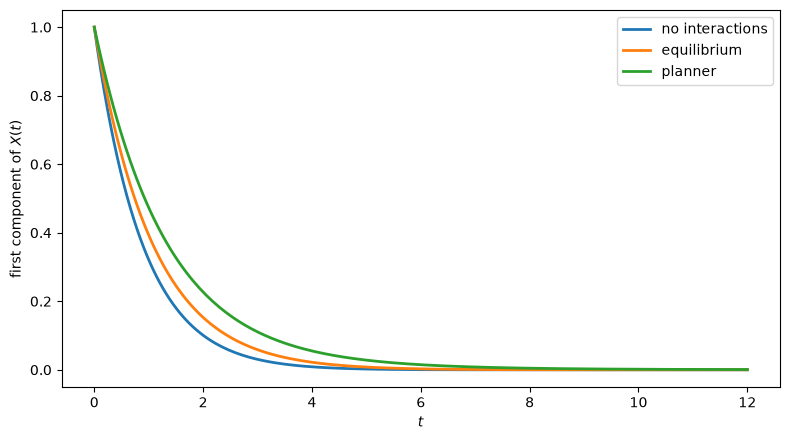

In [16]:
X0 = np.array([1.0, 0.5])
times = np.linspace(0, 12, 200)

paths = {'no interactions': G, 'equilibrium': JG, 'planner': JG_planner}

fig, ax = plt.subplots(figsize=(8, 4.5))
for label, M in paths.items():
    traj = np.array([expm(M*t) @ X0 for t in times])
    ax.plot(times, traj[:, 0], lw=2, label=label)
ax.set_xlabel('$t$')
ax.set_ylabel('first component of $X(t)$')
ax.legend()
plt.tight_layout()
plt.show()

## 具有金博尔需求的多产品定价

我们的第二个例子是多维的，它带来了一个惊喜。

{cite:t}`AlvarezArgente2026` 研究了连续统的"商店"，每个商店以恒定边际成本 $z_j$ 销售 $n$ 种产品。

商店内的产品由弹性为 $\bar\eta_d$ 的 CES 价格指数加总，而商店则由对称的金博尔加总器加总 {cite}`Kimball1995`。

设 $\eta_D(y)$ 为商店需求相对于其相对价格的弹性，设 $\bar\eta_D > 1$ 和 $\bar\eta_D'$ 分别表示其在对称点的水平和导数。

导数 $\bar\eta_D'$ 是需求的**超弹性**，这也是金博尔需求在定价模型中被广泛使用的原因：正的超弹性意味着，价格高于平均水平的商店面临更具弹性的需求，这会阻止它偏离大众。

这就是价格上的战略互补性，也是 {cite:t}`KlenowWillis2016` 及随后大量文献用来解释实际刚性的机制。

用 $x$ 和 $X$ 表示商店价格和平均商店价格相对于灵活价格水平 $\bar p_i = \bar z_i \bar\eta_D/(\bar\eta_D-1)$ 的对数偏差，用 $\bar s$ 表示稳态支出份额向量，曲率矩阵为

```{math}
:label: mfg_kimball_Q
\begin{aligned}
Q &= (\bar\eta_D - 1)\left[\left(\bar\eta_D - \bar\eta_d
+ \frac{\bar\eta_D'}{\bar\eta_D-1}\right)\bar s\bar s^\top
+ \bar\eta_d \operatorname{diag}(\bar s)\right] , \\
\Theta_X &= -\bar\eta_D' \, \bar s \bar s^\top , \\
Q + \Theta_X &= (\bar\eta_D-1)\left[(\bar\eta_D - \bar\eta_d)\bar s \bar s^\top
+ \bar\eta_d \operatorname{diag}(\bar s)\right] 。
\end{aligned}
```

盯着第三行看。

超弹性出现在 $Q$ 和 $\Theta_X$ 中，但在 $Q + \Theta_X$ 中却*消失了*。

根据 {prf:ref}`mfg_prop_riccati`，$Q+\Theta_X$ 之和是这两个矩阵到达总量动态的唯一渠道。

行动是价格的变化率，商店为改变价格支付二次的罗滕伯格成本。

矩阵 $\Gamma$ 使这一成本取决于改变的是哪一组价格，负的非对角元素代表了 {cite:t}`Midrigan2011` 和 {cite:t}`AlvarezLippi2014` 所强调的那种重新定价中的范围经济。

总量行动之间不存在相互作用，因此 $\Theta_{\mathcal A} = 0$，而非零的成本通胀率使 $A$ 为对角矩阵。

In [17]:
def kimball(η_d, η_D, η_D_prime, s):
    "Curvature and state-interaction matrices under Kimball demand."
    s = np.asarray(s, dtype=float)
    S = np.outer(s, s)
    Q = (η_D - 1)*((η_D - η_d + η_D_prime/(η_D - 1))*S + η_d*np.diag(s))
    Θ_X = -η_D_prime*S
    return Q, Θ_X

s_bar = np.array([0.5, 0.3, 0.2])       # three products, unequal shares
η_d, η_D = 6.0, 4.0                     # within-store and across-store elasticities
ρ_K, π_K = 0.04, 0.02                   # discount rate and cost inflation

n_K = len(s_bar)
A_K = π_K*np.eye(n_K)
B_K = np.eye(n_K)
Γ_K = 20.0*(np.eye(n_K) - 0.25*(np.ones((n_K, n_K)) - np.eye(n_K)))

print("Rotemberg cost matrix Γ =\n", Γ_K)
print("\neigenvalues of Γ:", np.linalg.eigvalsh(Γ_K).round(4))

Rotemberg cost matrix Γ =
 [[20. -5. -5.]
 [-5. 20. -5.]
 [-5. -5. 20.]]

eigenvalues of Γ: [10. 25. 25.]


### 超弹性和总量动态

现在将超弹性在一个很宽的范围内扫描，包括一个负值，观察什么在改变，什么没有改变。

In [18]:
print(f"{'η_D′':>6}  {'eigenvalues of Q':>28}  {'eigenvalues of Q + Θ_X':>28}")
for η_Dp in (-3.0, 0.0, 3.0, 10.0):
    Q_K, Θ_K = kimball(η_d, η_D, η_Dp, s_bar)
    print(f"{η_Dp:>6}  {str(np.linalg.eigvalsh(Q_K).round(3)):>28}"
          f"  {str(np.linalg.eigvalsh(Q_K + Θ_K).round(3)):>28}")

  η_D′              eigenvalues of Q        eigenvalues of Q + Θ_X
  -3.0           [2.598 4.5   7.482]           [3.127 4.766 7.827]
   0.0           [3.127 4.766 7.827]           [3.127 4.766 7.827]
   3.0           [3.435 5.096 8.329]           [3.127 4.766 7.827]
  10.0        [ 3.714  5.694 10.112]           [3.127 4.766 7.827]


自身曲率矩阵 $Q$ 变化很大，$\Theta_X$ 也随之变化，但有效曲率根本没有变化。

因此总量价格动态对超弹性是不变的。

In [19]:
print(f"{'η_D′':>6}  {'aggregate eigenvalues':>34}  {'individual eigenvalues':>34}")
for η_Dp in (-3.0, 0.0, 3.0, 10.0):
    Q_K, Θ_K = kimball(η_d, η_D, η_Dp, s_bar)
    P_K = mfg_riccati(A_K, B_K, Q_K + Θ_K, Γ_K, ρ_K)
    β2_K = mfg_riccati(A_K, B_K, Q_K, Γ_K, ρ_K)
    ev_agg = np.sort(np.linalg.eigvals(closed_loop(A_K, B_K, Γ_K, P_K)).real)
    ev_ind = np.sort(np.linalg.eigvals(closed_loop(A_K, B_K, Γ_K, β2_K)).real)
    print(f"{η_Dp:>6}  {str(ev_agg.round(4)):>34}  {str(ev_ind.round(4)):>34}")

  η_D′               aggregate eigenvalues              individual eigenvalues
  -3.0           [-0.6527 -0.4882 -0.3836]           [-0.5813 -0.4752 -0.3815]
   0.0           [-0.6527 -0.4882 -0.3836]           [-0.6527 -0.4882 -0.3836]
   3.0           [-0.6527 -0.4882 -0.3836]           [-0.7234 -0.4928 -0.3844]
  10.0           [-0.6527 -0.4882 -0.3836]           [-0.8713 -0.4966 -0.3853]


左边一组数字在每一行中都相同，而右边一组则不是。

超弹性改变了单个商店的行为方式，但没有改变行业的行为方式。

几乎所有的变化都集中在单一模式中，因为 $\Theta_X$ 是秩一的，并指向方向 $\bar s$，即商店自身以份额加权的价格指数。

其余涉及商店内部相对价格的模式几乎不变。

### 静态互补性

值得了解我们正在改变的静态互补性有多大。

对静态利润函数最大化给出最优反应 $x^{*}(X) = -Q^{-1}\Theta_X X$，{cite:t}`AlvarezArgente2026` 表明

```{math}
:label: mfg_kimball_br
\frac{\partial x_i^{*}(X)}{\partial X_j} = \bar s_j \frac{\kappa}{1+\kappa},
\qquad
\kappa \equiv \frac{\bar\eta_D'}{(\bar\eta_D-1)\bar\eta_D} 。
```

In [20]:
print(f"{'η_D′':>6}{'pass-through':>14}   best response matrix, first row")
for η_Dp in (-3.0, 0.0, 3.0, 10.0):
    Q_K, Θ_K = kimball(η_d, η_D, η_Dp, s_bar)
    BR = -np.linalg.solve(Q_K, Θ_K)
    κ = η_Dp/((η_D - 1)*η_D)
    BR_closed = κ/(1 + κ)*np.outer(np.ones(n_K), s_bar)
    assert np.allclose(BR, BR_closed)
    print(f"{η_Dp:>6}{BR.sum(axis=1)[0]:>14.4f}   {BR[0].round(4)}")

print("\nΘ_X symmetric:      ", np.allclose(Θ_K, Θ_K.T))
print("best response symmetric:", np.allclose(BR, BR.T))

  η_D′  pass-through   best response matrix, first row
  -3.0       -0.3333   [-0.1667 -0.1    -0.0667]
   0.0        0.0000   [0. 0. 0.]
   3.0        0.2000   [0.1  0.06 0.04]
  10.0        0.4545   [0.2273 0.1364 0.0909]

Θ_X symmetric:       True
best response symmetric: False


在这些行中，静态转嫁率从 $-33\%$ 变到 $+45\%$，且随超弹性变化符号，但每一个这样的经济体都具有完全相同的总量动态。

因此，那种认为静态互补性越强、总量传播就越大的直觉是不可靠的。

还请注意，最优反应矩阵*不是*对称的，因为不同产品的份额不同，而 $\Theta_X$ 始终是对称的。

$\Theta_X$ 的对称性正是 {prf:ref}`mfg_prop_planner` 所需要的，即使静态博弈看起来不对称，它也依然成立。

### 闭式特征值

由于 $A_K$ 是单位矩阵的倍数且 $B_K = I$，总量特征值与标量情形具有相同的形式，$(\Gamma+\Theta_{\mathcal A})^{-1}(Q+\Theta_X)$ 的每一个特征值 $\omega_i$ 对应一个：

$$
\lambda_i = \frac\rho2 - \sqrt{\left(\frac\rho2 + a\right)^2 + \omega_i} 。
$$

In [21]:
Q_K, Θ_K = kimball(η_d, η_D, 3.0, s_bar)
P_K = mfg_riccati(A_K, B_K, Q_K + Θ_K, Γ_K, ρ_K)
JG_K = closed_loop(A_K, B_K, Γ_K, P_K)

ω = np.linalg.eigvals(np.linalg.solve(Γ_K, Q_K + Θ_K)).real
predicted = np.sort(ρ_K/2 - np.sqrt((ρ_K/2 + π_K)**2 + ω))

print("eigenvalues of the closed-loop matrix:", np.sort(np.linalg.eigvals(JG_K).real).round(6))
print("from the closed-form formula:         ", predicted.round(6))

eigenvalues of the closed-loop matrix: [-0.652659 -0.488188 -0.383578]
from the closed-form formula:          [-0.652659 -0.488188 -0.383578]


{ref}`mfg_ex8` 提出当不同产品之间通胀率不同时（此时 $A$ 是对角矩阵但不是单位矩阵的倍数）会发生什么。

### 总量和个体价格路径

分解 {eq}`mfg_decomposition` 将商店的价格分为行业平均值 $X$ 和其自身的偏离 $z = x - X$。

前者遵循均衡矩阵 $P$，后者遵循单代理人矩阵 $\bar\beta_2$。

因此我们发现的不变性应该表现为行业的路径相同，而偏离常态的商店的路径不同。

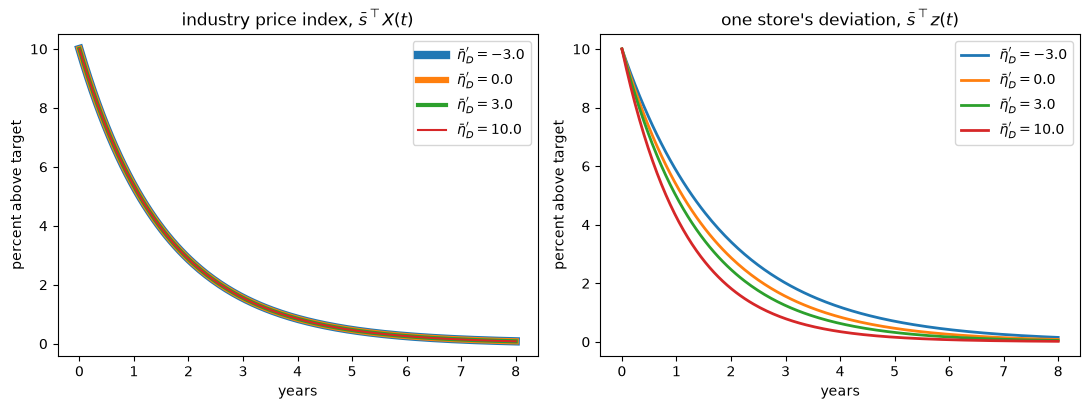

In [22]:
t_K = np.linspace(0, 8, 200)
shock = 0.10*np.ones(n_K)      # ten percent above target, all products

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for k, η_Dp in enumerate((-3.0, 0.0, 3.0, 10.0)):
    Q_K, Θ_K = kimball(η_d, η_D, η_Dp, s_bar)
    P_K = mfg_riccati(A_K, B_K, Q_K + Θ_K, Γ_K, ρ_K)
    β2_K = mfg_riccati(A_K, B_K, Q_K, Γ_K, ρ_K)
    U_XX = closed_loop(A_K, B_K, Γ_K, P_K)
    U_zz = closed_loop(A_K, B_K, Γ_K, β2_K)
    agg = np.array([s_bar @ expm(U_XX*t) @ shock for t in t_K])
    dev = np.array([s_bar @ expm(U_zz*t) @ shock for t in t_K])
    label = f"$\\bar\\eta_D' = {η_Dp}$"
    # decreasing line widths, so that four coincident curves remain visible
    axes[0].plot(t_K, 100*agg, lw=6 - 1.5*k, label=label)
    axes[1].plot(t_K, 100*dev, lw=2, label=label)

axes[0].set_title('industry price index, $\\bar s^\\top X(t)$')
axes[1].set_title("one store's deviation, $\\bar s^\\top z(t)$")
for ax in axes:
    ax.set_xlabel('years')
    ax.set_ylabel('percent above target')
    ax.legend()
plt.tight_layout()
plt.show()

左侧面板中的四条曲线完全重叠。

右侧面板中的四条曲线则不然：超弹性越高，商店弥合自身价格与行业价格之间的缺口就越快。

微观和宏观的价格灵活性由不同的对象支配，而只有微观的那个对超弹性做出反应。

### 计划者确实在乎

将相互作用加倍给了计划者有效曲率 $Q + 2\Theta_X = (Q + \Theta_X) - \bar\eta_D' \bar s\bar s^\top$，它*确实*依赖于超弹性。

In [23]:
print(f"{'η_D′':>6}  {'eig(Q + 2Θ_X)':>26}  {'planner eigenvalues':>32}")
for η_Dp in (-3.0, 0.0, 3.0, 10.0, 20.0):
    Q_K, Θ_K = kimball(η_d, η_D, η_Dp, s_bar)
    M = Q_K + 2*Θ_K
    P_p = mfg_riccati(A_K, B_K, M, Γ_K, ρ_K)
    ev = np.sort(np.linalg.eigvals(closed_loop(A_K, B_K, Γ_K, P_p)).real)
    flag = "" if np.linalg.eigvalsh(M).min() > 0 else "   <- not positive definite"
    print(f"{η_Dp:>6}  {str(np.linalg.eigvalsh(M).round(3)):>26}"
          f"  {str(ev.round(4)):>32}{flag}")

  η_D′               eig(Q + 2Θ_X)               planner eigenvalues
  -3.0         [3.435 5.096 8.329]         [-0.7234 -0.4928 -0.3844]
   0.0         [3.127 4.766 7.827]         [-0.6527 -0.4882 -0.3836]
   3.0         [2.598 4.5   7.482]         [-0.5813 -0.4752 -0.3815]
  10.0         [0.654 4.211 7.054]         [-0.5132 -0.3931 -0.2383]
  20.0      [-2.788  4.092  6.816]         [-0.5055 -0.3881  8.4685]   <- not positive definite


因此，均衡对超弹性的不敏感性是均衡所特有的。

计划者本会做的与行业实际所做之间的差距，随着超弹性的上升而扩大，在最后一行中，计划者的有效曲率已经不再是正定的，返回的矩阵也不再能使系统稳定。

{ref}`mfg_ex7` 精确定位了这一阈值，并从静态转嫁的角度对其作出解释。


## 总量冲击和识别

现在加入一个同时冲击所有人的冲击。

设 $\mathcal J$ 是一个补偿跳跃过程，并假设

$$
dx = (B\alpha - Ax)dt + \Sigma^{1/2}dW + \Upsilon \, d\mathcal J 。
$$

在有共同噪声的情况下，价值函数必须同时跟踪总量状态和个体状态，因此它变成 $v(x, X)$。

尽管如此，在递归 HJB 方程中匹配系数会得到一个值得强调的结果。

```{prf:proposition}
:label: mfg_prop_common_noise

在存在共同噪声的情况下，支配总量动态的矩阵 $P$ 满足与之前*相同*的均衡里卡蒂方程。
```

这是一个熟悉的确定性等价结果，与线性二次控制中的结果类似。

它还给出了一个清晰的分解。

用 $z = x - X$ 表示代理人偏离横截面均值的偏差，

```{math}
:label: mfg_decomposition
\begin{aligned}
dX &= \left(\Lambda P - A\right) X dt + \Upsilon d\mathcal J , \\
dz &= \left(B\Gamma^{-1}B^\top\bar\beta_2 - A\right) z \, dt + \Sigma^{1/2}dW , \\
\alpha &= (\Gamma+\Theta_{\mathcal A})^{-1}B^\top P X + \Gamma^{-1}B^\top\bar\beta_2 z 。
\end{aligned}
```

仔细看第二行。

代理人偏离均值的偏差动态涉及 $\bar\beta_2$，即*单代理人*里卡蒂方程的解，两个相互作用矩阵都没有出现。

对 $z$ 做出反应的那部分行动也是如此。

```{prf:proposition}
:label: mfg_prop_identification

关于 $x(t) - X(t)$ 和 $\alpha(t)-\mathcal A(t)$ 的数据不包含关于 $\Theta_X$ 或 $\Theta_{\mathcal A}$ 的任何信息。
```

这是"缺失截距"问题的一个尖锐表述。

从微观数据中去除时间效应——这是控制总量条件的标准方法——恰好去除了识别战略相互作用所需的变异。

相反，总量数据确实携带这一信息，可以与微观数据结合来恢复它。

In [24]:
# reduced-form matrices that an econometrician could estimate
U_XX = closed_loop(A, B, Γ + Θ_A, P)            # drift of the aggregate state
U_zz = closed_loop(A, B, Γ, β2)                 # drift of the deviation from the mean

print("aggregate drift U_XX =\n", U_XX.round(4))
print("\ndeviation drift U_zz =\n", U_zz.round(4))

# now double the state interaction and recompute
P_alt = mfg_riccati(A, B, Q + 2*Θ_X, Γ + Θ_A, ρ)
print("\nwith Θ_X doubled:")
print("  aggregate drift changes: ",
      not np.allclose(U_XX, closed_loop(A, B, Γ + Θ_A, P_alt)))
print("  deviation drift changes: ",
      not np.allclose(U_zz, closed_loop(A, B, Γ, β2)))

aggregate drift U_XX =
 [[-0.8403 -0.178 ]
 [-0.0692 -0.7045]]

deviation drift U_zz =
 [[-1.0597 -0.1326]
 [-0.0174 -0.8423]]

with Θ_X doubled:
  aggregate drift changes:  True
  deviation drift changes:  False


{ref}`mfg_ex4` 展示了如何从总量数据中恢复 $\Theta_X$，以及为什么没有归一化就无法区分 $\Theta_X$ 和 $\Theta_{\mathcal A}$。

## 练习

```{exercise}
:label: mfg_ex1

公式 {eq}`mfg_scalar_existence` 和 {eq}`mfg_scalar_stability` 将标量模型划分为四个区域。

定义

$$
-\theta^{*} \equiv q + a(a+\rho)\frac{\gamma+\theta_{\mathcal A}}{b^2},
\qquad
-\theta^{**} \equiv q + \left(\frac\rho2+a\right)^2\frac{\gamma+\theta_{\mathcal A}}{b^2} 。
$$

取 $\rho = 0.5$, $a = 0.3$, $b = 1$, $q = 1$, $\gamma = 1$, $\theta_{\mathcal A}=0$。

1. 计算 $\theta^{*}$ 和 $\theta^{**}$，并验证 $-\theta^{**} = -\theta^{*} + (\rho/2)^2(\gamma+\theta_{\mathcal A})/b^2$。
1. 对于每个阈值两侧的 $\theta_X$ 值，计算 $\lambda$ 并对结果进行分类：稳定、单位根、发散但可接受，或不存在均衡。
1. 当不存在均衡时，`mfg_riccati` 会怎么做？
1. 绘制 $\lambda$ 对 $\theta_X$ 的图，并标出这些阈值。
```

```{solution-start} mfg_ex1
:class: dropdown
```

In [25]:
ρ_e, a_e, b_e, q_e, γ_e, θA_e = 0.5, 0.3, 1.0, 1.0, 1.0, 0.0

θ_star = -(q_e + a_e*(a_e + ρ_e)*(γ_e + θA_e)/b_e**2)
θ_ss = -(q_e + (ρ_e/2 + a_e)**2*(γ_e + θA_e)/b_e**2)

print(f"θ*  = {θ_star:.4f}")
print(f"θ** = {θ_ss:.4f}")
print(f"gap = {θ_star - θ_ss:.4f}, "
      f"(ρ/2)²(γ+θ_A)/b² = {(ρ_e/2)**2*(γ_e + θA_e)/b_e**2:.4f}")

θ*  = -1.2400
θ** = -1.3025
gap = 0.0625, (ρ/2)²(γ+θ_A)/b² = 0.0625


In [26]:
for θ_X in (0.5, -0.5, θ_star, -1.27, -1.31):
    inside = (ρ_e/2 + a_e)**2 + b_e**2*(q_e + θ_X)/(γ_e + θA_e)
    if inside < 0:
        print(f"θ_X = {θ_X:+.4f}: no equilibrium")
        continue
    λ = ρ_e/2 - np.sqrt(inside)
    if λ < -1e-9:
        kind = "stable, X converges to zero"
    elif abs(λ) <= 1e-9:
        kind = "unit root, X stays where it starts"
    else:
        kind = "divergent but admissible"
    print(f"θ_X = {θ_X:+.4f}: λ = {λ:+.5f}   {kind}")

θ_X = +0.5000: λ = -1.09257   stable, X converges to zero
θ_X = -0.5000: λ = -0.64582   stable, X converges to zero
θ_X = -1.2400: λ = -0.00000   unit root, X stays where it starts
θ_X = -1.2700: λ = +0.06972   divergent but admissible
θ_X = -1.3100: no equilibrium


在 $\theta^{**}$ 以下不存在实根，求解器会报告失败，而不是返回一个虚假的答案。

In [27]:
try:
    mfg_riccati(np.array([[a_e]]), np.array([[b_e]]),
                np.array([[q_e - 1.31]]), np.array([[γ_e]]), ρ_e)
except Exception as e:
    print(f"solver raises {type(e).__name__} when no equilibrium exists")

solver raises LinAlgError when no equilibrium exists


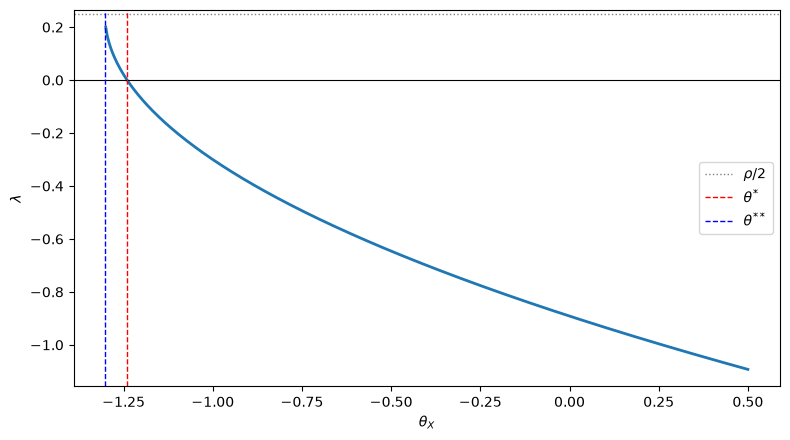

In [28]:
θ_grid = np.linspace(-1.30, 0.5, 400)
inside = (ρ_e/2 + a_e)**2 + b_e**2*(q_e + θ_grid)/(γ_e + θA_e)
λ_grid = np.where(inside >= 0, ρ_e/2 - np.sqrt(np.maximum(inside, 0)), np.nan)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(θ_grid, λ_grid, lw=2)
ax.axhline(0, color='k', lw=0.8)
ax.axhline(ρ_e/2, color='grey', ls=':', lw=1, label=r'$\rho/2$')
ax.axvline(θ_star, color='r', ls='--', lw=1, label=r'$\theta^{*}$')
ax.axvline(θ_ss, color='b', ls='--', lw=1, label=r'$\theta^{**}$')
ax.set_xlabel(r'$\theta_X$')
ax.set_ylabel(r'$\lambda$')
ax.legend()
plt.tight_layout()
plt.show()

沿横轴向左移动意味着状态互补性更强。

持久性平稳上升，直至 $\theta^{*}$ 处，此时总量状态停止收敛；在 $\theta^{*}$ 和 $\theta^{**}$ 之间，均衡路径发散，但发散得足够慢以保持贴现收益有限；在 $\theta^{**}$ 以下则完全不存在均衡。

```{solution-end}
```

```{exercise}
:label: mfg_ex2

讲座表明状态中更强的互补性提高了闭环矩阵的*迹*。

它是否也提高了每一个特征值？

绘制许多随机的二维经济体：取 $B = I$，令 $Q$ 和 $\Gamma$ 为随机正定矩阵，令 $\Theta_X$ 为随机负定矩阵，设置 $\rho = 0.05$。

对每次抽样，将相互作用为 $\Theta_X$ 的均衡与相互作用为 $1.5\,\Theta_X$ 的均衡进行比较，只保留两个均衡都存在且可接受的那些抽样。

报告迹上升的频率和*每个*特征值都上升的频率。
```

```{solution-start} mfg_ex2
:class: dropdown
```

In [29]:
rng = np.random.default_rng(3)
trace_rose = eig_rose = kept = 0

for _ in range(400):
    A_r = rng.normal(size=(2, 2))*0.3 + 0.4*np.eye(2)
    B_r = np.eye(2)
    M = rng.normal(size=(2, 2)); Q_r = M @ M.T + 0.5*np.eye(2)
    M = rng.normal(size=(2, 2)); Γ_r = M @ M.T + 0.5*np.eye(2)
    M = rng.normal(size=(2, 2)); Θ_r = -0.2 * (M @ M.T)

    try:
        P0 = mfg_riccati(A_r, B_r, Q_r + Θ_r, Γ_r, 0.05)
        P1 = mfg_riccati(A_r, B_r, Q_r + 1.5*Θ_r, Γ_r, 0.05)
    except Exception:
        continue

    J0 = closed_loop(A_r, B_r, Γ_r, P0)
    J1 = closed_loop(A_r, B_r, Γ_r, P1)
    if max(np.linalg.eigvals(J0).real.max(), np.linalg.eigvals(J1).real.max()) >= 0.025:
        continue

    kept += 1
    trace_rose += np.trace(J1) > np.trace(J0) - 1e-10
    e0 = np.sort(np.linalg.eigvals(J0).real)
    e1 = np.sort(np.linalg.eigvals(J1).real)
    eig_rose += np.all(e1 >= e0 - 1e-10)

print(f"admissible draws:            {kept}")
print(f"trace rose:                  {trace_rose}/{kept}")
print(f"every eigenvalue rose:       {eig_rose}/{kept}")

admissible draws:            347
trace rose:                  345/347
every eigenvalue rose:       293/347


迹的结果在每次抽样中都成立，正如理论所要求的那样。

逐个特征值的单调性在相当一部分情况下失败。

原因是 $Q+\Theta_X$ 和 $B(\Gamma+\Theta_{\mathcal A})^{-1}B^\top$ 不一定可交换，因此问题不会分解为独立的一维问题，一个总体上减缓调整的变化仍可能在某个方向上加速调整。

额外的限制——例如标量漂移矩阵 $A = a I$——可以逐个模式地恢复单调性。

```{solution-end}
```

```{exercise}
:label: mfg_ex3

将计划者与分散均衡进行比较。

使用讲座中的二维例子，计算以下四种情形下均衡和计划者的闭环矩阵的特征值：

1. 仅状态互补，$\Theta_X \prec 0$ 且 $\Theta_{\mathcal A}=0$
1. 仅行动替代，$\Theta_X = 0$ 且 $\Theta_{\mathcal A} = 0.2 I$
1. 仅行动互补，$\Theta_X = 0$ 且 $\Theta_{\mathcal A} = -0.2 I$
1. 两者均互补

在哪些情形下计划者的配置比均衡更持久？请解释。
```

```{solution-start} mfg_ex3
:class: dropdown
```

In [30]:
def eigen_pair(Θ_X_use, Θ_A_use):
    "Closed-loop eigenvalues for the equilibrium and for the planner."
    P_eq = mfg_riccati(A, B, Q + Θ_X_use, Γ + Θ_A_use, ρ)
    P_pl = mfg_riccati(A, B, Q + 2*Θ_X_use, Γ + 2*Θ_A_use, ρ)
    e_eq = np.sort(np.linalg.eigvals(closed_loop(A, B, Γ + Θ_A_use, P_eq)).real)
    e_pl = np.sort(np.linalg.eigvals(closed_loop(A, B, Γ + 2*Θ_A_use, P_pl)).real)
    return e_eq, e_pl

zero = np.zeros((2, 2))
cases = {'states, complements':  (Θ_X, zero),
         'actions, substitutes': (zero,  0.2*np.eye(2)),
         'actions, complements': (zero, -0.2*np.eye(2)),
         'both complements':     (Θ_X, -0.2*np.eye(2))}

print(f"{'case':24}{'equilibrium':>22}{'planner':>22}   planner slower?")
for label, (tx, ta) in cases.items():
    e_eq, e_pl = eigen_pair(tx, ta)
    slower = bool(np.all(e_pl >= e_eq - 1e-12))
    print(f"{label:24}{str(e_eq.round(4)):>22}{str(e_pl.round(4)):>22}   {slower}")

case                               equilibrium               planner   planner slower?
states, complements          [-0.9584 -0.673 ]     [-0.8522 -0.4287]   True
actions, substitutes         [-0.9933 -0.7741]     [-0.9344 -0.7284]   True
actions, complements         [-1.1748 -0.9088]     [-1.3325 -1.0151]   False
both complements             [-1.0426 -0.7346]     [-1.0137 -0.4958]   True


仅存在状态互补性时，计划者的配置更持久。

计划者认识到，当一个代理人远离稳态时，其他代理人也乐于远离稳态，因此没有那么迫切要回归。

仅存在*行动*互补性时，比较结果反转，计划者调整得更快：计划者将以下事实内在化——当一个代理人调整时，其他代理人也想调整。

行动替代性的情形是最后一种情形的镜像，同样使计划者更慢。

当状态和行动都存在互补性时，两种力量相互对抗。

在这个校准中，状态相互作用占主导地位，计划者仍然更慢，但这个排序是一个数量上的偶然，而非定理：一般来说，计划者与均衡持久性之间的比较无法确定符号。

```{solution-end}
```

```{exercise}
:label: mfg_ex4

本练习贯穿 {prf:ref}`mfg_prop_identification` 及其推论。

1. 验证当 $\Theta_X$ 和 $\Theta_{\mathcal A}$ 改变时，代理人偏离横截面均值的偏差漂移保持不变。
1. 假设计量经济学家知道 $\rho$、$Q$、$A$、$B$、$\Gamma$ 和 $\Theta_{\mathcal A}$，并估计出总量漂移矩阵 $U_{\dot X, X}$。展示如何恢复 $\Theta_X$，并用数值方法验证你的步骤。
1. 在标量模型中，证明 $\theta_X$ 和 $\theta_{\mathcal A}$ 无法分别识别：构造一族参数对，它们产生完全相同的总量动态*和*完全相同的策略系数。
```

```{solution-start} mfg_ex4
:class: dropdown
```

对于第一部分，偏差漂移为 $B\Gamma^{-1}B^\top\bar\beta_2 - A$，而 $\bar\beta_2$ 满足单代理人里卡蒂方程 {eq}`mfg_beta2`，其中不出现任何相互作用矩阵。

In [31]:
for label, (tx, ta) in {'baseline': (Θ_X, Θ_A),
                        'very different': (3*Θ_X, -0.1*np.eye(2))}.items():
    β2_case = mfg_riccati(A, B, Q, Γ, ρ)        # does not depend on tx, ta
    print(f"{label:16}: U_zz =", closed_loop(A, B, Γ, β2_case).round(6).tolist())

baseline        : U_zz = [[-1.059657, -0.132645], [-0.017424, -0.842298]]
very different  : U_zz = [[-1.059657, -0.132645], [-0.017424, -0.842298]]


对于第二部分，反转闭环矩阵的定义得到 $P$，然后从均衡里卡蒂方程中读出 $\Theta_X$：

$$
P = \Lambda^{-1}\left(U_{\dot X, X} + A\right),
\qquad
\Theta_X = P\Lambda P - Q - \rho P - PA - A^\top P 。
$$

In [32]:
U_obs = closed_loop(A, B, Γ + Θ_A, P)      # what the econometrician estimates

P_hat = np.linalg.solve(Λ, U_obs + A)
Θ_X_hat = P_hat @ Λ @ P_hat - Q - ρ*P_hat - P_hat @ A - A.T @ P_hat

print("true Θ_X =\n", Θ_X.round(6))
print("\nrecovered Θ_X =\n", Θ_X_hat.round(6))
print(f"\nmaximum error: {np.abs(Θ_X - Θ_X_hat).max():.2e}")

true Θ_X =
 [[-0.3   0.05]
 [ 0.05 -0.2 ]]

recovered Θ_X =
 [[-0.3   0.05]
 [ 0.05 -0.2 ]]

maximum error: 2.22e-16


对于第三部分，公式 {eq}`mfg_scalar_lambda` 表明 $\lambda$ 只通过比率 $(q+\theta_X)/(\gamma+\theta_{\mathcal A})$ 依赖于这两个相互作用。

保持该比率不变会描绘出一族可观察等价的经济体。

策略系数无法打破这种平局，因为 $\lambda = b\,U_{\alpha,X} - a$ 将其与 $\lambda$ 绑定在一起。

In [33]:
ratio = (q + (-0.4))/(γ + 0.3)       # baseline θ_X = -0.4, θ_A = 0.3

print(f"{'θ_A':>7}{'θ_X':>12}{'λ':>12}{'policy coeff':>15}")
for θ_A_alt in (0.3, 0.0, 0.6, 1.0):
    θ_X_alt = ratio*(γ + θ_A_alt) - q
    λ_alt = scalar_lambda(ρ_s, a, b, q, γ, θ_X_alt, θ_A_alt)
    print(f"{θ_A_alt:>7.2f}{θ_X_alt:>12.6f}{λ_alt:>12.6f}{(λ_alt + a)/b:>15.6f}")

    θ_A         θ_X           λ   policy coeff
   0.30   -0.400000   -0.728103      -0.428103
   0.00   -0.538462   -0.728103      -0.428103
   0.60   -0.261538   -0.728103      -0.428103
   1.00   -0.076923   -0.728103      -0.428103


每一行描述了一个不同的经济体，具有不同数量的状态和行动战略互补性，但它们全都产生完全相同的总量动态和相同的策略规则。

要区分它们需要对其中一种相互作用进行归一化，或引入外部信息。

```{solution-end}
```

```{exercise}
:label: mfg_ex5

本练习推导了我们在校准资本积累例子时简单假设的两个曲率。

假设调整成本为

$$
\psi(i) = \frac{\phi}{2}\,\bar i\left(\frac{i - \bar i}{\bar i}\right)^2 ,
$$

因此 $\psi'(\bar i) = 0$，$\psi''(\bar i) = \phi/\bar i$，并假设投资品以恒定弹性 $\varepsilon_s$ 供给，

$$
\mathcal P(I) = \left(\frac{I}{\bar i}\right)^{1/\varepsilon_s} 。
$$

1. 利用稳态欧拉方程 $\Pi_k(\bar k, \bar k) = \rho + \delta$ 证明 $\bar k^{1-\nu} = \nu(\eta-1)/[\eta(\rho+\delta)]$，然后证明

$$
\gamma = \phi\,\delta\bar k^{1-\nu} , \qquad
\theta_{\mathcal A} = \frac{\delta \bar k^{1-\nu}}{\varepsilon_s} 。
$$

1. 哪一组 $(\phi, \varepsilon_s)$ 能再现校准值 $\gamma = 0.05$ 和 $\theta_{\mathcal A} = 0.09$？
1. 证明具有相同 $\phi + 1/\varepsilon_s$ 值的所有参数对都产生完全相同的*总量*动态，并用数值方法验证它们尽管如此仍蕴含不同的个体投资规则和不同的计划者配置。
```

```{solution-start} mfg_ex5
:class: dropdown
```

对于第一部分，$\Pi_k(k,K) = \nu\frac{\eta-1}{\eta}k^{\nu(1-1/\eta)-1}K^{\nu/\eta}$，因此在对角线上 $\Pi_k(\bar k,\bar k) = \nu\frac{\eta-1}{\eta}\bar k^{\nu-1}$。

将其设为等于 $\rho+\delta$（这是当 $\mathcal P(\bar i) = 1$ 且 $\psi'(\bar i) = 0$ 时的稳态使用者成本），得到 $\bar k^{1-\nu}$ 的表达式。

由于 $\bar\Pi = \bar k^{\nu}$ 且 $\bar i = \delta\bar k$，

$$
\gamma = \frac{\delta^2\bar k^2}{\bar k^{\nu}}\frac{\phi}{\delta \bar k}
= \phi\,\delta\bar k^{1-\nu} ,
\qquad
\theta_{\mathcal A} = \frac{\delta^2\bar k^2}{\bar k^{\nu}}
\frac{1}{\varepsilon_s \delta\bar k} = \frac{\delta\bar k^{1-\nu}}{\varepsilon_s} 。
$$

In [34]:
scale_c = δ_c*ν_c*(η_c - 1)/(η_c*(ρ_c + δ_c))      # δ k̄^{1-ν}

print(f"δ k̄^(1-ν) = {scale_c:.4f}")
print(f"φ   implied by γ = {γ_c}:   {γ_c/scale_c:.4f}")
print(f"ε_s implied by θ_A = {θ_A_c}: {scale_c/θ_A_c:.4f}")

δ k̄^(1-ν) = 0.3500
φ   implied by γ = 0.05:   0.1429
ε_s implied by θ_A = 0.09: 3.8889


该校准对应于一个适度凸的调整成本 $\phi = 0.14$，以及大约 $3.9$ 的投资供给弹性。

对于第三部分，$\gamma + \theta_{\mathcal A} = \delta\bar k^{1-\nu}(\phi + 1/\varepsilon_s)$，而根据 {eq}`mfg_scalar_lambda`，对 $\lambda$ 而言只有这个和是重要的。

但个体的里卡蒂方程 {eq}`mfg_beta2` 单独涉及 $\gamma$，而计划者的方程涉及 $\gamma + 2\theta_{\mathcal A}$，因此两者都能区分这些参数对。

In [35]:
print(f"{'φ':>6}{'1/ε_s':>8}{'aggregate':>12}{'individual':>12}{'planner':>10}")
for φ, inv_ε in ((0.40, 0.00), (0.30, 0.10), (1/7, 0.257143), (0.05, 0.35)):
    γ_case, θ_A_case = φ*scale_c, inv_ε*scale_c
    λ_agg = scalar_lambda(ρ_c, δ_c, δ_c, q_c, γ_case, θ_X_c, θ_A_case)
    λ_ind = scalar_lambda(ρ_c, δ_c, δ_c, q_c, γ_case, 0.0, 0.0)
    λ_pl = scalar_lambda(ρ_c, δ_c, δ_c, q_c, γ_case, 2*θ_X_c, 2*θ_A_case)
    print(f"{φ:>6.3f}{inv_ε:>8.3f}{λ_agg:>12.6f}{λ_ind:>12.6f}{λ_pl:>10.4f}")

     φ   1/ε_s   aggregate  individual   planner
 0.400   0.000   -0.138936   -0.157859   -0.1175
 0.300   0.100   -0.138936   -0.173431   -0.1142
 0.143   0.257   -0.138936   -0.230930   -0.1109
 0.050   0.350   -0.138936   -0.372649   -0.1096


总量动态完全相同，精确到最后一位数字，而个体行为则从迟缓到几乎没有摩擦不等。

只拥有总量数据的计量经济学家无法区分资本品市场的拥挤与昂贵的安装技术，这正是 {prf:ref}`mfg_prop_identification` 的标量版本。

```{solution-end}
```

```{exercise}
:label: mfg_ex6

上图右侧面板表明，当规模报酬接近不变时会发生一些特殊的事情。

1. 证明对于每一个 $\eta > 1$，当 $\nu \to 1$ 时 $q + \theta_X \to 0$，$\lambda \to -\delta$。
1. 证明在同一极限下，总量投资对资本缺口的反应 $(\lambda+\delta)/\delta$ 趋于零。
1. 用经济学术语解释这一极限。
```

```{solution-start} mfg_ex6
:class: dropdown
```

第一部分从 {eq}`mfg_capital_coeffs` 立即可得：$q + \theta_X = \frac{\eta-1}{\eta}\nu(1-\nu) \to 0$，而由 $a = b = \delta$，

$$
\lambda \to \frac\rho2 - \sqrt{\left(\frac\rho2 + \delta\right)^2} = -\delta 。
$$

对于第二部分，{eq}`mfg_aggregate_action` 的标量版本给出 $\mathcal A = \frac{\lambda+\delta}{\delta}X$，当 $\lambda \to -\delta$ 时该式趋于零。

In [36]:
print(f"{'ν':>8}{'q + θ_X':>10}{'λ':>10}{'half-life':>11}{'A/X':>9}")
for ν in (0.7, 0.9, 0.99, 0.999, 0.99999):
    λ_ν = scalar_lambda(ρ_c, δ_c, δ_c, cap_q(η_c, ν), γ_c, cap_θ_X(η_c, ν), θ_A_c)
    print(f"{ν:>8}{cap_q(η_c,ν) + cap_θ_X(η_c,ν):>10.5f}{λ_ν:>10.5f}"
          f"{half_life(λ_ν):>11.3f}{(λ_ν + δ_c)/δ_c:>9.4f}")

       ν   q + θ_X         λ  half-life      A/X
     0.7   0.15750  -0.13894      4.989  -0.3894
     0.9   0.06750  -0.11799      5.875  -0.1799
    0.99   0.00743  -0.10210      6.789  -0.0210
   0.999   0.00075  -0.10021      6.917  -0.0021
 0.99999   0.00001  -0.10000      6.931  -0.0000


对于第三部分，请注意 $q + \theta_X = -\bar k^2\left[\Pi_{kk} + \Pi_{kK}\right]/\bar\Pi$ 衡量的是沿*对角线*的利润曲率，即当整个行业一同扩张时，资本边际盈利能力下降的速率。

当 $\nu = 1$ 时，利润函数 {eq}`mfg_capital_profit` 是关于 $(k, K)$ 联合一次齐次的，因此 $\Pi_k(k,k)$ 根本不依赖于 $k$。

那么，全行业范围内的资本缺口就不会产生以不同方式进行投资的激励，缺口只能通过折旧来弥合。

有效曲率为零，经济体恰好位于 {eq}`mfg_scalar_existence` 中存在性区域的边界上，均衡仍然是唯一且稳定的，$\lambda = -\delta$。

```{solution-end}
```

```{exercise}
:label: mfg_ex7

在金博尔例子中，均衡的有效曲率 $Q + \Theta_X$ 对每一个超弹性都是正定的，但计划者的 $Q + 2\Theta_X$ 却不是。

1. 利用 $Q + 2\Theta_X = (Q+\Theta_X) - \bar\eta_D'\,\bar s\bar s^\top$，证明它是正定的当且仅当
$\bar\eta_D'\,\bar s^\top(Q+\Theta_X)^{-1}\bar s < 1$。
1. 证明 $(Q+\Theta_X)\mathbb{1} = (\bar\eta_D-1)\bar\eta_D\,\bar s$，其中 $\mathbb{1}$ 是全一向量，因而该条件为 $\bar\eta_D' < (\bar\eta_D-1)\bar\eta_D$。
1. 证明这恰好是 {eq}`mfg_kimball_br` 中静态转嫁率低于二分之一的条件，并用数值方法验证该阈值。
```

```{solution-start} mfg_ex7
:class: dropdown
```

对于第一部分，如果 $\bar\eta_D' \leq 0$，秩一项是相加而非相减，正定性是立即成立的。

如果 $\bar\eta_D' > 0$，那么对于 $M \succ 0$，矩阵 $M - c vv^\top$（$c>0$）是正定的当且仅当 $c\, v^\top M^{-1}v < 1$，这可以从行列式恒等式 $\det(M - cvv^\top) = \det(M)(1 - c\,v^\top M^{-1}v)$ 应用于每个主子块推出，或者直接从有边界矩阵的舒尔补推出。

对于第二部分，在 {eq}`mfg_kimball_Q` 的第三行中利用 $\bar s^\top\mathbb{1} = 1$，

$$
(Q+\Theta_X)\mathbb{1}
= (\bar\eta_D-1)\left[(\bar\eta_D-\bar\eta_d)\bar s + \bar\eta_d \bar s\right]
= (\bar\eta_D-1)\bar\eta_D\,\bar s 。
$$

因此 $(Q+\Theta_X)^{-1}\bar s = \mathbb{1}/[(\bar\eta_D-1)\bar\eta_D]$，从而

$$
\bar s^\top(Q+\Theta_X)^{-1}\bar s = \frac{1}{(\bar\eta_D-1)\bar\eta_D} ,
$$

这将第一部分中的条件转化为 $\bar\eta_D' < (\bar\eta_D-1)\bar\eta_D$。

对于第三部分，该不等式恰好说明 $\kappa < 1$，且 $\kappa/(1+\kappa)$ 关于 $\kappa$ 递增，在 $\kappa = 1$ 处取值 $1/2$。

总静态转嫁率为 $\sum_j \partial x_i^{*}/\partial X_j = \kappa/(1+\kappa)$，因为份额之和为一，因此当商店将行业范围价格上涨转嫁到自身价格的比例不到一半时，计划者的问题恰好表现良好。

In [37]:
lo, hi = 0.0, 100.0
for _ in range(60):
    mid = (lo + hi)/2
    Q_m, Θ_m = kimball(η_d, η_D, mid, s_bar)
    if np.linalg.eigvalsh(Q_m + 2*Θ_m).min() > 0:
        lo = mid
    else:
        hi = mid

κ_star = lo/((η_D - 1)*η_D)
print(f"threshold by bisection:  η_D′ = {lo:.6f}")
print(f"(η_D - 1) η_D         =        {(η_D - 1)*η_D:.6f}")
print(f"κ at the threshold    = {κ_star:.6f}")
print(f"pass-through there    = {κ_star/(1 + κ_star):.6f}")

threshold by bisection:  η_D′ = 12.000000
(η_D - 1) η_D         =        12.000000
κ at the threshold    = 1.000000
pass-through there    = 0.500000


```{solution-end}
```

```{exercise}
:label: mfg_ex8

金博尔例子中的闭式特征值使用了 $A = \pi I$。

将其替换为 $A = \operatorname{diag}(0.00, 0.02, 0.06)$，使得三种产品面临不同的成本通胀率。

1. 检验闭式公式是否失效。
1. 检验*持久性*一节中迹的比较静态是否仍然成立，方法是对 $\Theta_X$ 进行缩放，并记录闭环矩阵的迹和特征值。
1. 总量动态对超弹性的不变性是否依然成立？
```

```{solution-start} mfg_ex8
:class: dropdown
```

In [38]:
A_het = np.diag([0.00, 0.02, 0.06])
Q_h, Θ_h = kimball(η_d, η_D, 3.0, s_bar)

P_h = mfg_riccati(A_het, B_K, Q_h + Θ_h, Γ_K, ρ_K)
JG_h = closed_loop(A_het, B_K, Γ_K, P_h)

ω_h = np.linalg.eigvals(np.linalg.solve(Γ_K, Q_h + Θ_h)).real
print("closed-loop eigenvalues:", np.sort(np.linalg.eigvals(JG_h).real).round(5))
print("closed-form formula:    ",
      np.sort(ρ_K/2 - np.sqrt((ρ_K/2 + np.diag(A_het))**2 + np.sort(ω_h))).round(5))

closed-loop eigenvalues: [-0.6519  -0.48847 -0.38891]
closed-form formula:     [-0.65622 -0.48819 -0.38209]


该公式不再成立：当 $A$ 不是单位矩阵的倍数时，没有单一的标量位移可以放到根号内，而 $A$ 与 $Q+\Theta_X$ 的特征向量不一定一致。

由于三种通胀率相互接近，此处的误差较小，但它们是系统性的，并且随 $A$ 的离散程度增大而增大。

另一方面，迹的结果不需要这样的限制。

In [39]:
print(f"{'scale on Θ_X':>14}{'trace':>10}   eigenvalues")
for scale in (0.0, 0.5, 1.0, 1.5):
    P_s = mfg_riccati(A_het, B_K, Q_h + scale*Θ_h, Γ_K, ρ_K)
    JG_s = closed_loop(A_het, B_K, Γ_K, P_s)
    print(f"{scale:>14}{np.trace(JG_s):>10.5f}   "
          f"{np.sort(np.linalg.eigvals(JG_s).real).round(5)}")

  scale on Θ_X     trace   eigenvalues
           0.0  -1.60539   [-0.723   -0.49291 -0.38948]
           0.5  -1.56838   [-0.68798 -0.49116 -0.38924]
           1.0  -1.52928   [-0.6519  -0.48847 -0.38891]
           1.5  -1.48769   [-0.6153  -0.48399 -0.3884 ]


提高比例增强了互补性并提高了迹，这与前面的二维例子完全一致。

对于第三部分，不变性与 $A$ 无关：它来自于 $\bar\eta_D'$ 在 $Q + \Theta_X$ 中的抵消，而 {prf:ref}`mfg_prop_riccati` 表明只有 $Q+\Theta_X$ 和 $\Gamma+\Theta_{\mathcal A}$ 会进入均衡里卡蒂方程。

In [40]:
for η_Dp in (-3.0, 0.0, 3.0, 10.0):
    Q_i, Θ_i = kimball(η_d, η_D, η_Dp, s_bar)
    P_i = mfg_riccati(A_het, B_K, Q_i + Θ_i, Γ_K, ρ_K)
    ev = np.sort(np.linalg.eigvals(closed_loop(A_het, B_K, Γ_K, P_i)).real)
    print(f"η_D′ = {η_Dp:>5}:  {ev.round(6)}")

η_D′ =  -3.0:  [-0.651898 -0.488473 -0.388911]
η_D′ =   0.0:  [-0.651898 -0.488473 -0.388911]
η_D′ =   3.0:  [-0.651898 -0.488473 -0.388911]
η_D′ =  10.0:  [-0.651898 -0.488473 -0.388911]


```{solution-end}
```


## 延伸阅读

{cite:t}`AlvarezArgente2026` 发展了本讲座中的结果，以及我们在上文中实现的两个经济学例子。

他们还将分析扩展到通过横截面分布的高阶矩进行的相互作用。

{cite:t}`CarmonaDelarue2018` 对平均场博弈给出了全面的概率论处理，{cite:t}`AchdouEtAl2022` 描述了当模型不是线性二次时，用于求解耦合偏微分方程的数值方法。